# 1 · Training the ransomware classifier, step by step

This notebook is the *look under the hood* companion to `make train`. It trains a
**small** XGBoost model on exactly the same features and the same split as the real
pipeline (a few seconds), shows you how to read the metrics, and points out what the
real pipeline adds on top (hyper-parameter search, early stopping, calibration).

Run it from the repository root:

```bash
make setup download preprocess     # once: venv + dataset + processed features
jupyter lab notebooks/01_train_the_classifier.ipynb
```

Everything here is offline: no LLM, no API keys, no network.


In [1]:
# Make the project importable no matter where Jupyter was started from.
import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "utils" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("repo root:", ROOT)


repo root: /home/faddy/Desktop/githubrepos/ransomware-rationale


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

from src.utils.config import Paths
from src.utils.seed import set_seed

set_seed(42)
plt.rcParams["figure.figsize"] = (7, 4)


## 1. Load the data

`make preprocess` turned the raw `data/raw/CIC-MalMem-2022.csv` (58,596 rows × 57
columns) into three parquet files, one per split, plus `features.json` — the ordered
list of the 55 numeric columns the model actually uses (the label columns are dropped).


In [3]:
features = json.loads((Paths.processed / "features.json").read_text())
train = pd.read_parquet(Paths.processed / "train.parquet")
val = pd.read_parquet(Paths.processed / "val.parquet")
test = pd.read_parquet(Paths.processed / "test.parquet")

print(f"{len(features)} features")
print(f"rows  train/val/test = {len(train)}/{len(val)}/{len(test)}")
print("feature names (first 12):", ", ".join(features[:12]), "...")


55 features
rows  train/val/test = 40540/5813/11670
feature names (first 12): pslist.nproc, pslist.nppid, pslist.avg_threads, pslist.nprocs64bit, pslist.avg_handlers, dlllist.ndlls, dlllist.avg_dlls_per_proc, handles.nhandles, handles.avg_handles_per_proc, handles.nport, handles.nfile, handles.nevent ...


## 2. What is one row?

One row = **one memory image**, summarised by counts and averages produced by
Volatility memory-forensics plugins (`pslist`, `dlllist`, `handles`, `malfind`,
`ldrmodules`, `svcscan`, `callbacks`, …). There is no raw bytes here — just these
56 numbers. That is why the classifier is a tabular model (XGBoost) and not a
neural network over the dump.


In [4]:
peek = ["pslist.nproc", "dlllist.ndlls", "handles.nhandles", "malfind.ninjections",
        "malfind.commitCharge", "ldrmodules.not_in_mem_avg", "svcscan.nservices",
        "callbacks.ncallbacks"]
train[peek].describe().T[["mean", "std", "min", "50%", "max"]].round(3)


,mean,std,min,50%,max
pslist.nproc,41.406,5.539,21.000,41.000,240.000
dlllist.ndlls,1813.889,329.017,670.000,1743.000,3443.000
handles.nhandles,10294.127,5656.088,3514.000,9493.000,1047310.000
malfind.ninjections,7.170,16.548,1.000,4.000,627.000
malfind.commitCharge,1002.044,6145.748,1.000,4.000,220850.000
ldrmodules.not_in_mem_avg,0.033,0.009,0.016,0.032,0.441
svcscan.nservices,391.374,4.659,94.000,392.000,395.000
callbacks.ncallbacks,86.912,3.134,51.000,87.000,89.000


## 3. What are the labels?

The task is **binary: `y_binary == 1` means ransomware**, `0` means everything else.
Read that carefully: *Benign* is 0, but so are Trojan and Spyware captures. A `0`
from this model means "not ransomware", **not** "clean" — a distinction that matters
the moment you use this in real triage.


In [5]:
print("label counts (train):")
print(train["y_binary"].value_counts().rename({0: "not ransomware", 1: "ransomware"}).to_string())
print()
print("what the 0s actually are (train):")
print(pd.crosstab(train["malware_class"], train["y_binary"]).to_string())


label counts (train):
y_binary
not ransomware    33870
ransomware         6670

what the 0s actually are (train):
y_binary           0     1
malware_class             
Benign         20473     0
Ransomware         0  6670
Spyware         6827     0
Trojan          6570     0


## 4. Why the split is made by capture group, not by row

Every malware row in this mirror comes from a named capture
(`Ransomware-Shade-<hash>-7.raw`) and each capture contributes ~10 answer rows that
are near-duplicates. If those landed in both train and test you would measure
memorisation, not detection. `make preprocess` therefore splits **70/10/20 by capture
group** — the check below is the whole reason the model's ROC-AUC is 0.93 here
instead of the 0.99 you see in papers that split by row.


In [6]:
overlap = set(train["group_id"]) & set(test["group_id"])
print(f"groups train/test = {train['group_id'].nunique()}/{test['group_id'].nunique()}")
print(f"overlapping groups between train and test: {len(overlap)}")


groups train/test = 22763/6504
overlapping groups between train and test: 0


## 5. Train a small model

The real `make train` runs `RandomizedSearchCV` (30 trials, 3-fold, PR-AUC, ~226 s),
then early stopping on a 10 % slice → 191 trees, then refits on all of train. To keep
this notebook quick we reuse the hyper-parameters that search found
(`models/best_params.json`) and train 200 trees directly.


In [7]:
from xgboost import XGBClassifier

best = json.loads((Paths.models / "best_params.json").read_text())["params"]
print("best params from the search:", best)

t0 = time.time()
model = XGBClassifier(tree_method="hist", n_jobs=4, random_state=42,
                      n_estimators=200, eval_metric="logloss", **best)
model.fit(train[features].to_numpy(np.float32), train["y_binary"].to_numpy())
print(f"trained {model.n_estimators} trees in {time.time() - t0:.1f}s")


best params from the search: {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
trained 200 trees in 3.5s


## 6. Evaluate on the held-out test split

* **ROC-AUC** — ranking quality over all thresholds (0.5 = coin flip).
* **PR-AUC** (average precision) — the one to watch when the positive class is the
  minority; it punishes a model that just cries ransomware.
* **Confusion matrix** — how many false negatives (ransomware called benign) you get.


In [8]:
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, roc_auc_score)

X_test = test[features].to_numpy(np.float32)
y_test = test["y_binary"].to_numpy()
p_test = model.predict_proba(X_test)[:, 1]

print(f"ROC-AUC : {roc_auc_score(y_test, p_test):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, p_test):.4f}")
cm = confusion_matrix(y_test, p_test >= 0.5)
print(f"\nconfusion matrix (threshold 0.5):\n{cm}")
print(f"  TN={cm[0, 0]}  FP={cm[0, 1]}  FN={cm[1, 0]}  TP={cm[1, 1]}")
print()
print(classification_report(y_test, p_test >= 0.5, target_names=["not ransomware", "ransomware"],
                            digits=3))


ROC-AUC : 0.9271
PR-AUC  : 0.6978

confusion matrix (threshold 0.5):
[[9176  598]
 [ 739 1157]]
  TN=9176  FP=598  FN=739  TP=1157

                precision    recall  f1-score   support

not ransomware      0.925     0.939     0.932      9774
    ransomware      0.659     0.610     0.634      1896

      accuracy                          0.885     11670
     macro avg      0.792     0.775     0.783     11670
  weighted avg      0.882     0.885     0.884     11670



## 7. Is the probability honest? (calibration)

A raw gradient-boosted score is *not* a probability: values crowd near 0 and 1. The
real pipeline therefore fits `CalibratedClassifierCV(..., method="sigmoid")` on the
validation split and hands the calibrated model to everything downstream (the
evidence builder, the rationales, the CLI). Here we compare the raw model with the
calibrated one that `make train` saved.


Brier score  raw=0.0824   calibrated=0.0849   (lower is better)


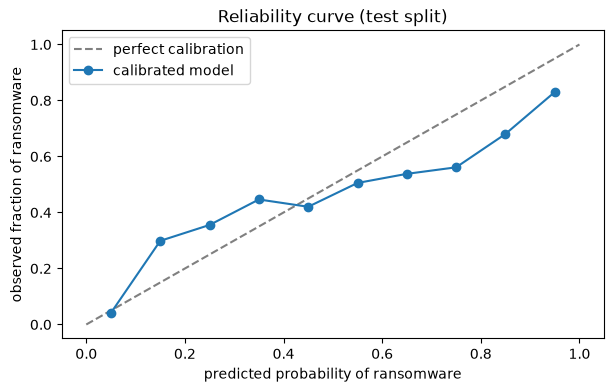

In [9]:
from src.models.calibrate import calibrated_proba, load

calibrator = load(Paths.models / "calibrator.joblib")
p_cal = calibrated_proba(calibrator, X_test)

def brier(p):
    return float(np.mean((p - y_test) ** 2))

print(f"Brier score  raw={brier(p_test):.4f}   calibrated={brier(p_cal):.4f}   (lower is better)")

bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(p_cal, bins) - 1, 0, 9)
obs = [y_test[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)]
fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.plot(bins[:-1] + 0.05, obs, "o-", label="calibrated model")
ax.set_xlabel("predicted probability of ransomware")
ax.set_ylabel("observed fraction of ransomware")
ax.set_title("Reliability curve (test split)")
ax.legend()
fig.savefig(Paths.figs / "notebook01_reliability.png", dpi=110, bbox_inches="tight")
plt.show()


## 8. Which features drive the verdict? (SHAP)

The evidence the LLM explains is built from **exact TreeSHAP** values: for one
prediction, every feature gets a contribution in log-odds space, and
`sum(contributions) + base_value` reproduces the model's raw score. Averaging
|SHAP| over many rows gives the global importance you see below — this is what the
project's top-6 evidence list is cut from.


/home/faddy/Desktop/githubrepos/ransomware-rationale/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-11 01:51:14,354 INFO shap_builder: SHAP via shap.TreeExplainer (n=300, f=55)


SHAP implementation: shap.TreeExplainer


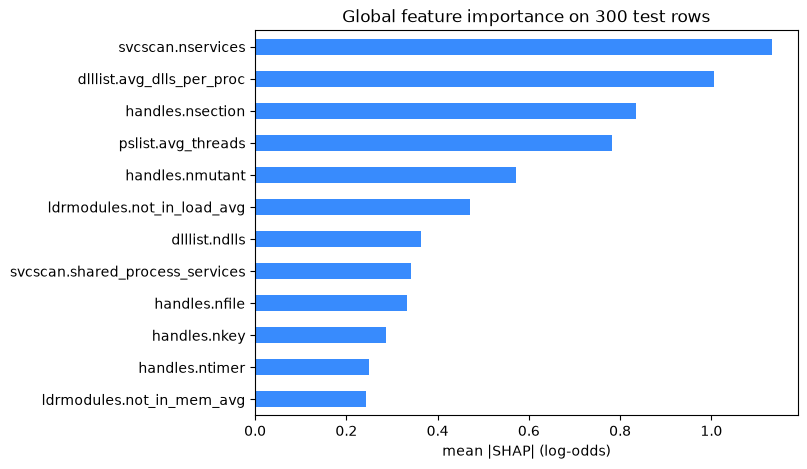

svcscan.nservices                  1.1324
dlllist.avg_dlls_per_proc          1.0065
handles.nsection                   0.8357
pslist.avg_threads                 0.7826
handles.nmutant                    0.5712
ldrmodules.not_in_load_avg         0.4719
dlllist.ndlls                      0.3628
svcscan.shared_process_services    0.3411
handles.nfile                      0.3324
handles.nkey                       0.2860
handles.ntimer                     0.2505
ldrmodules.not_in_mem_avg          0.2426
dtype: float64

In [10]:
from src.evidence.shap_builder import compute_shap

sample_idx = np.random.RandomState(0).choice(len(test), size=300, replace=False)
sv, base, impl = compute_shap(model, X_test[sample_idx], features)
importance = pd.Series(np.abs(sv).mean(axis=0), index=features).sort_values(ascending=False)

print("SHAP implementation:", impl)
fig, ax = plt.subplots(figsize=(7, 5))
importance.head(12)[::-1].plot.barh(ax=ax, color="#388bfd")
ax.set_xlabel("mean |SHAP| (log-odds)")
ax.set_title("Global feature importance on 300 test rows")
fig.savefig(Paths.figs / "notebook01_importance.png", dpi=110, bbox_inches="tight")
plt.show()
importance.head(12).round(4)


## 9. What this notebook skipped — and what to run instead

| step in `make train` | what it does | why it matters |
|---|---|---|
| `RandomizedSearchCV` (30 trials, 3-fold, PR-AUC) | tunes depth / learning rate / subsample / regularisation | the fixed params used above are its output |
| early stopping on a 10 % train slice | picks the tree count (191) instead of guessing | avoids overfitting the majority class |
| sigmoid calibration on the validation split | turns scores into usable probabilities | the reported probability is what the LLM must quote |
| `make evidence` | runs TreeSHAP for the 50 evaluation samples and writes the top-6 evidence tables | this is the LLM's *only* input |

Next steps:

* **`notebooks/02_check_a_sample_end_to_end.ipynb`** — take one sample through
  verdict → evidence → explanation → faithfulness check.
* **`python -m src.cli check --sample test_030109`** — the same path from the shell,
  against the model `make train` actually saved.
* **`make train FORCE=1`** — reproduce the full tuned model, then read
  `outputs/classifier_report.md`.
